<a href="https://colab.research.google.com/github/diegocortes30/olist_ecommerce_analysis/blob/main/notebooks/04_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 – Analysis

**Project:** Olist Brazilian E-Commerce Analysis

**Goal:** answer the five business questions with pandas and charts, and test whether late deliveries explain low review scores.

**Input:** the 8 clean files in `processed/` (output of notebook 03).

**Output:** one table with one row per order (`orders_master.csv`) and 6 charts.

**How this notebook works:**
1. Load the clean tables.
2. Build `orders_master`: reviews, items and payments are first summarized to one row per order and then joined, so no order is counted twice.
3. Answer each question with a chart and a short finding.

Revenue = sum of `price` (shipping excluded), counting only orders that are not `canceled` or `unavailable`.

## 1. Setup

In [76]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROCESSED = '/content/drive/MyDrive/Olist/processed'
FIGURES = '/content/drive/MyDrive/Olist/figures'
os.makedirs(FIGURES, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [77]:
orders = pd.read_csv(f'{PROCESSED}/orders_clean.csv',
                     parse_dates=['order_purchase_timestamp', 'order_approved_at',
                                  'order_delivered_carrier_date',
                                  'order_delivered_customer_date',
                                  'order_estimated_delivery_date'])
order_items = pd.read_csv(f'{PROCESSED}/order_items_clean.csv',
                          parse_dates=['shipping_limit_date'])
order_reviews = pd.read_csv(f'{PROCESSED}/order_reviews_clean.csv',
                          parse_dates=['review_creation_date',
                                       'review_answer_timestamp'])
customers = pd.read_csv(f'{PROCESSED}/customers_clean.csv',
                        dtype={'customer_zip_code_prefix': str})
sellers = pd.read_csv(f'{PROCESSED}/sellers_clean.csv',
                     dtype={'seller_zip_code_prefix': str})
order_payments = pd.read_csv(f'{PROCESSED}/order_payments_clean.csv')
products = pd.read_csv(f'{PROCESSED}/products_clean.csv')
product_category = pd.read_csv(f'{PROCESSED}/product_category_name_translation_clean.csv')

In [78]:
# Check that the shapes match notebook 03
print('orders:', orders.shape)
print('order_items:', order_items.shape)
print('order_reviews:', order_reviews.shape)
print('customers:', customers.shape)
print('sellers:', sellers.shape)
print('order_payments:', order_payments.shape)
print('products:', products.shape)
print('product_category:', product_category.shape)

orders: (99441, 9)
order_items: (112650, 7)
order_reviews: (99224, 7)
customers: (99441, 5)
sellers: (3095, 4)
order_payments: (103886, 7)
products: (32951, 9)
product_category: (74, 2)


In [79]:
# Check if the dtype in orders is correct
orders.dtypes

,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]
missing_delivery_date,bool


In [80]:
# Check if the prefixes have 5 digits
customers['customer_zip_code_prefix'].str.len().value_counts()

,count
customer_zip_code_prefix,
5,99441


## 2. Table creation

### 2.1. Reviews table

In [81]:
# Group order_reviews by order_id
reviews_per_order = order_reviews.groupby('order_id').agg(avg_review_score=('review_score', 'mean'),
                                                          n_reviews=('review_id', 'count')).reset_index()
reviews_per_order.shape

(98673, 3)

In [82]:
reviews_per_order.head()

,order_id,avg_review_score,n_reviews
0,00010242fe8c5a6d1ba2dd792cb16214,5.0,1
1,00018f77f2f0320c557190d7a144bdd3,4.0,1
2,000229ec398224ef6ca0657da4fc703e,5.0,1
3,00024acbcdf0a6daa1e931b038114c75,4.0,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0,1


### 2.2. Items table

In [83]:
# Group order items by order_id
items_per_order = order_items.groupby('order_id').agg(n_items=('order_item_id', 'count'),
                                                   total_price=('price', 'sum'),
                                                      total_freight=('freight_value', 'sum')).reset_index()
items_per_order.shape

(98666, 4)

In [84]:
items_per_order.head()

,order_id,n_items,total_price,total_freight
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14


### 2.3. Payments table

In [85]:
# Group order_payments by order_id
payments_per_order = order_payments.groupby('order_id').agg(total_payment=('payment_value', 'sum'),
                                                            n_payments=('payment_sequential', 'count'),
                                                            max_installments=('payment_installments', 'max')).reset_index()
payments_per_order.shape

(99440, 4)

In [86]:
payments_per_order.head()

,order_id,total_payment,n_payments,max_installments
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,1,2
1,00018f77f2f0320c557190d7a144bdd3,259.83,1,3
2,000229ec398224ef6ca0657da4fc703e,216.87,1,5
3,00024acbcdf0a6daa1e931b038114c75,25.78,1,2
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,1,3


### 2.4. Orders table

In [87]:
# Merge everything into one row per order
orders_master = (orders
                 .merge(customers, on='customer_id', how='left')
                 .merge(items_per_order, on='order_id', how='left')
                 .merge(reviews_per_order, on='order_id', how='left')
                 .merge(payments_per_order, on='order_id', how='left'))

orders_master.shape

(99441, 21)

In [88]:
# Look for null values
orders_master.isnull().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0
missing_delivery_date,0
customer_unique_id,0


In [89]:
# Filter orders_master where n_items is null
orders_master[orders_master['n_items'].isnull()]['order_status'].value_counts()

,count
order_status,
unavailable,603
canceled,164
created,5
invoiced,2
shipped,1


In [90]:
# Create column of delivery days
orders_master['delivery_days'] = (orders_master['order_delivered_customer_date'] -
                                  orders_master['order_purchase_timestamp']).dt.days

round(orders_master['delivery_days'].describe(),2)

,delivery_days
count,96476.00
mean,12.09
std,9.55
min,0.00
25%,6.00
50%,10.00
75%,15.00
max,209.00


In [91]:
orders_master[orders_master['delivery_days'].notnull()]['order_status'].value_counts()

,count
order_status,
delivered,96470
canceled,6


In [92]:
# Keep only delivered orders with a delivery date
delivered_ok = orders_master[(orders_master['order_status'] == 'delivered') & (orders_master['delivery_days'].notnull())].copy()
delivered_ok.shape

(96470, 22)

In [93]:
# Save orders_master csv
orders_master.to_csv(f'{PROCESSED}/orders_master.csv', index=False)

## 3. Do late orders get worse reviews?

In [94]:
# Flag orders delivered after the estimated date
delivered_ok['late_delivery'] = delivered_ok['order_delivered_customer_date'] > delivered_ok['order_estimated_delivery_date']
delivered_ok['late_delivery'].head()

,late_delivery
0,False
1,False
2,False
3,False
4,False


In [95]:
round(delivered_ok['late_delivery'].mean()*100,2)

np.float64(8.11)

In [96]:
round(delivered_ok.groupby('late_delivery')['avg_review_score'].agg(['mean', 'count']),2)

,mean,count
late_delivery,,
False,4.29,88163
True,2.57,7661


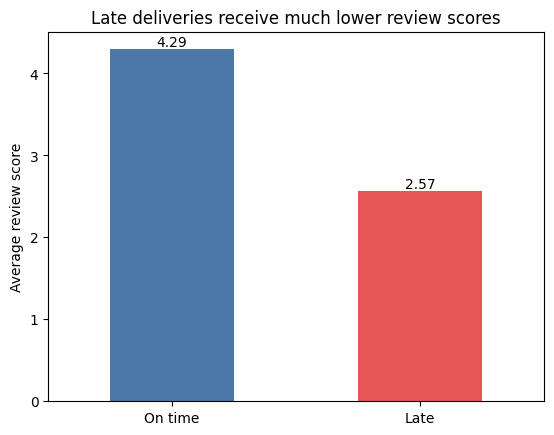

In [97]:
avg_score = delivered_ok.groupby('late_delivery')['avg_review_score'].mean()

ax = avg_score.plot(kind='bar', color=['#4C78A8', '#E45756'], rot=0)
ax.set_xticklabels(['On time', 'Late'])
ax.set_xlabel('')
ax.set_ylabel('Average review score')
ax.set_title('Late deliveries receive much lower review scores')
ax.bar_label(ax.containers[0], fmt='%.2f')

plt.savefig('delivery_vs_review.png', dpi=150, bbox_inches='tight')
plt.show()

**Findings:**

**Delivery vs. review score:** 8.1% of delivered orders arrived after the estimated date. Those orders have an average review score of 2.57, versus 4.29 for on-time orders (7,661 late orders vs 88,163 on time).

The gap (1.7 points) is much larger than the differences between product categories, so delivery performance is a major driver of customer satisfaction.

## 4. Which states generate the most revenue?

In [98]:
# Keep orders that count as sales (not canceled or unavailable)
sales = orders_master[~orders_master['order_status'].isin(['canceled', 'unavailable'])].copy()
sales.shape

(98207, 22)

In [99]:
# Group by state
revenue_by_state = sales.groupby('customer_state').agg(total_revenue=('total_price', 'sum')).reset_index()
revenue_by_state.sort_values('total_revenue', ascending=False, inplace=True)
revenue_by_state.reset_index(drop=True, inplace=True)
revenue_by_state.index += 1
revenue_by_state.head(10)

,customer_state,total_revenue
1,SP,5163867.22
2,RJ,1811623.42
3,MG,1573508.20
4,RS,742559.78
5,PR,676883.06
6,SC,518578.28
7,BA,507108.83
8,DF,300886.45
9,GO,287870.46
10,ES,273532.13


In [100]:
# % of each state
revenue_by_state['share_pct'] = round(revenue_by_state['total_revenue'] / revenue_by_state['total_revenue'].sum() * 100, 2)
revenue_by_state[['customer_state', 'share_pct']].head(10)

,customer_state,share_pct
1,SP,38.27
2,RJ,13.43
3,MG,11.66
4,RS,5.50
5,PR,5.02
6,SC,3.84
7,BA,3.76
8,DF,2.23
9,GO,2.13
10,ES,2.03


In [101]:
# Sum the top 3 states
revenue_by_state['share_pct'].head(3).sum()

np.float64(63.36)

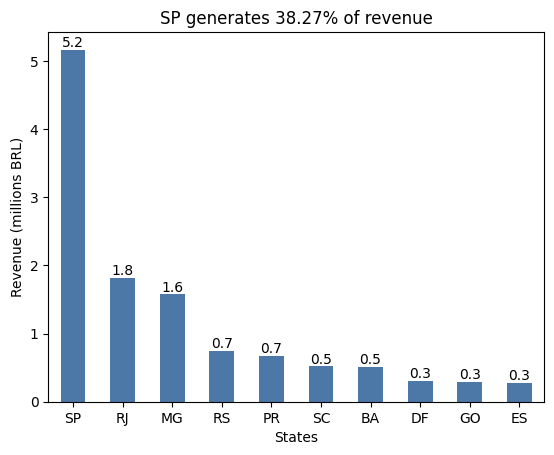

In [102]:
# Bar chart: top 10 states by revenue
top_10 = revenue_by_state.head(10).copy()
top_10['revenue_millions'] = top_10['total_revenue'] / 1_000_000

ax = top_10.plot(kind='bar', x='customer_state', y='revenue_millions',
                 color='#4C78A8', rot=0, legend=False)
ax.set_xlabel('States')
ax.set_ylabel('Revenue (millions BRL)')
ax.set_title('SP generates 38.27% of revenue')
ax.bar_label(ax.containers[0], fmt='%.1f')

plt.savefig('revenue_by_state.png', dpi=150, bbox_inches='tight')
plt.show()

**Findings:**

**Revenue by state:** SP alone generates 38.27% of revenue (5.16M BRL), and the top 3
states (SP, RJ, MG) account for 63.4%. Revenue is highly concentrated in the south-east.

## 5. How do orders and revenue change per month?

In [103]:
# Create year-month column
sales['year_month'] = sales['order_purchase_timestamp'].dt.to_period('M')
sales['year_month'].head()

,year_month
0,2017-10
1,2018-07
2,2018-08
3,2017-11
4,2018-02


In [104]:
# Count distinct months
sales['year_month'].nunique()

24

In [105]:
# Group by year_month
monthly = (sales.groupby('year_month').agg(n_orders=('order_id','count'),
                                          revenue=('total_price','sum')).reset_index())
monthly

,year_month,n_orders,revenue
0,2016-09,2,207.86
1,2016-10,293,44507.30
2,2016-12,1,10.90
3,2017-01,787,120098.27
4,2017-02,1718,244959.35
5,2017-03,2617,368341.32
6,2017-04,2377,353842.98
7,2017-05,3640,503159.19
8,2017-06,3205,429916.61
9,2017-07,3946,492287.30


In [106]:
# Keep Jan 2017 – Aug 2018 (months with enough orders)
monthly['month'] = monthly['year_month'].astype(str)
monthly_plot = monthly[(monthly['month'] >= '2017-01') & (monthly['month'] <= '2018-08')].copy()
monthly_plot.shape

(20, 4)

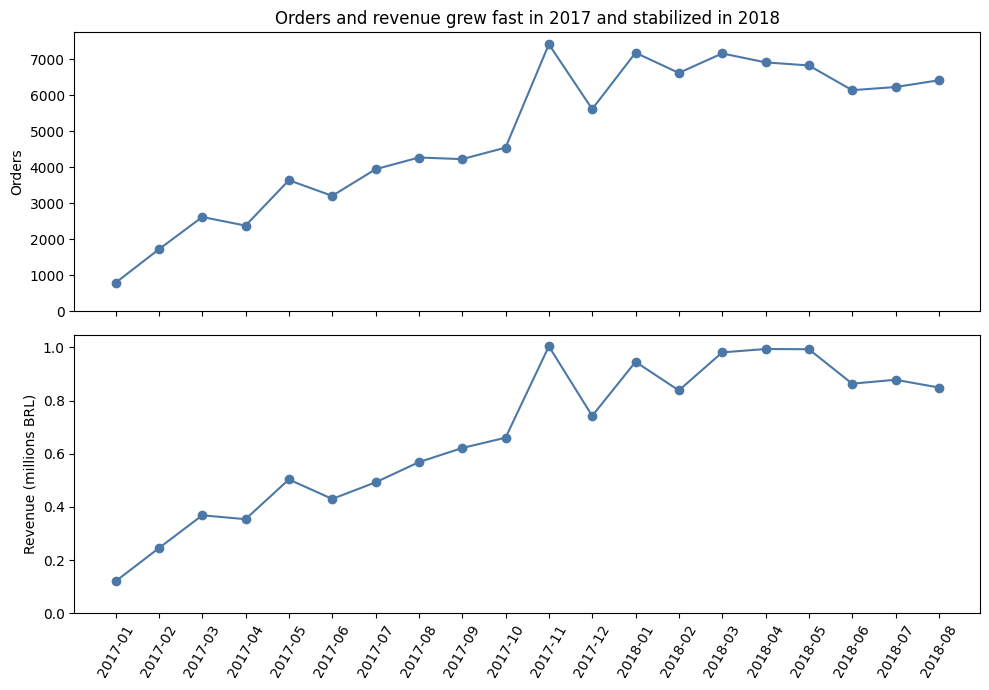

In [107]:
# Graph the results
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(monthly_plot['month'], monthly_plot['n_orders'], color='#4C78A8', marker='o')
axes[0].set_ylabel('Orders')
axes[0].set_title('Orders and revenue grew fast in 2017 and stabilized in 2018')

axes[1].plot(monthly_plot['month'], monthly_plot['revenue'] / 1_000_000, color='#4C78A8', marker='o')
axes[1].set_ylabel('Revenue (millions BRL)')

axes[0].set_ylim(bottom=0)
axes[1].set_ylim(bottom=0)
plt.xticks(rotation=60)
plt.tight_layout()

plt.savefig('monthly_trend.png', dpi=150, bbox_inches='tight')
plt.show()

**Findings:**

**Monthly trend:** orders and revenue grew quickly during 2017, from 787 orders
(120K BRL) in January to a peak of 7,423 orders (1.00M BRL) in November 2017, likely driven by Black Friday.

From 2018 on, volume stabilized around 6,100–7,200 orders per month, with a slight decline in revenue in mid-2018.

Months at the edges of the dataset (2016 and September 2018) have almost no orders and are excluded from the chart.

## 6. What share of orders is canceled?

In [108]:
# General rate
round((orders_master['order_status'] == 'canceled').mean() * 100, 2)

np.float64(0.63)

In [109]:
# Cancellation rate per month
orders_master['month'] = orders_master['order_purchase_timestamp'].dt.to_period('M').astype(str)
orders_master['is_canceled'] = (orders_master['order_status'] == 'canceled')
canceled_per_month = orders_master.groupby('month')['is_canceled'].agg(['sum', 'count', 'mean'])
canceled_per_month

,sum,count,mean
month,,,
2016-09,2,4,0.500000
2016-10,24,324,0.074074
2016-12,0,1,0.000000
2017-01,3,800,0.003750
2017-02,17,1780,0.009551
2017-03,33,2682,0.012304
2017-04,18,2404,0.007488
2017-05,29,3700,0.007838
2017-06,16,3245,0.004931


In [110]:
# Add percentage column
canceled_per_month = canceled_per_month.reset_index()
canceled_per_month['rate_pct'] = canceled_per_month['mean'] * 100

In [111]:
# Filter the months with enough orders
cancel_plot = canceled_per_month[(canceled_per_month['month'] >= '2017-01') &
                              (canceled_per_month['month'] <= '2018-08')].copy()
cancel_plot.shape

(20, 5)

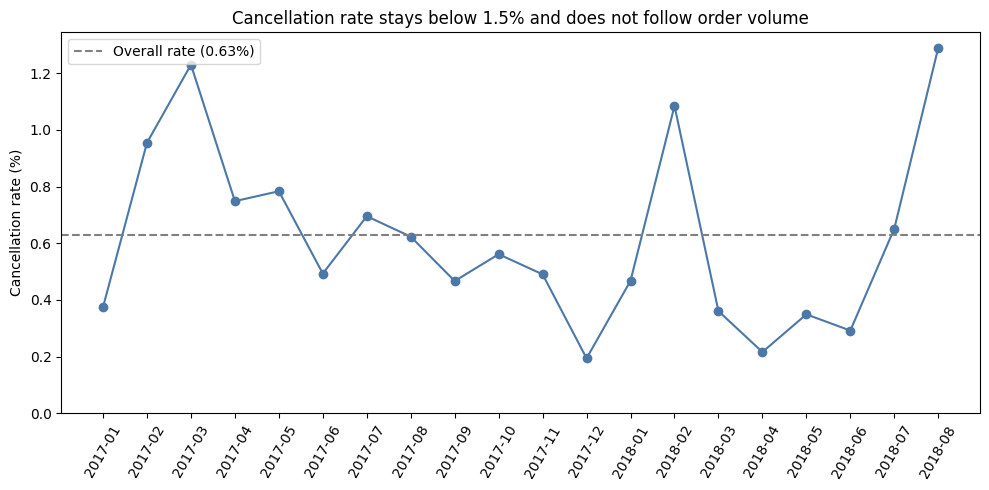

In [112]:
# Plot the results
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(cancel_plot['month'], cancel_plot['rate_pct'], color='#4C78A8', marker='o')
ax.axhline(0.63, linestyle='--', color='gray', label='Overall rate (0.63%)')

ax.set_ylim(bottom=0)
ax.set_ylabel('Cancellation rate (%)')
ax.set_title('Cancellation rate stays below 1.5% and does not follow order volume')
ax.legend()

plt.xticks(rotation=60)
plt.tight_layout()

plt.savefig('cancellation_rate.png', dpi=150, bbox_inches='tight')
plt.show()

In [113]:
# Check correlation
cancel_plot[['count', 'rate_pct']].corr()

,count,rate_pct
count,1.000000,-0.249065
rate_pct,-0.249065,1.000000


In [114]:
# Cancellation rate by state (states with at least 1,000 orders)
cancel_by_state = (orders_master.groupby('customer_state').agg(n_orders=('is_canceled', 'count'),
                                                               n_canceled=('is_canceled', 'sum'),
                                                               rate=('is_canceled', 'mean')).reset_index())
cancel_by_state['rate_pct'] = cancel_by_state['rate'] * 100

big_states = (cancel_by_state[cancel_by_state['n_orders'] >= 1000].sort_values('rate_pct', ascending=False).reset_index(drop=True))
big_states.index += 1
round(big_states, 2)

,customer_state,n_orders,n_canceled,rate,rate_pct
1,SP,41746,327,0.01,0.78
2,RJ,12852,86,0.01,0.67
3,GO,2020,13,0.01,0.64
4,MG,11635,64,0.01,0.55
5,CE,1336,7,0.01,0.52
6,SC,3637,19,0.01,0.52
7,BA,3380,16,0.00,0.47
8,RS,5466,25,0.00,0.46
9,ES,2033,9,0.00,0.44
10,PR,5045,22,0.00,0.44


**Findings:**

**Cancellations:** only 0.63% of orders are canceled. Between January 2017 and
August 2018 the monthly rate stays between 0.2% and 1.3%.

The highest rates appear in March 2017, February 2018 and August 2018, not in the months with the most orders (November 2017, the busiest month, has a below-average rate of 0.49%).

Months at the edges of the dataset (2016 and September–October 2018) have too few orders to be meaningful and are excluded.

The monthly cancellation rate shows only a weak negative correlation with order volume (-0.25, 20 months), so there is no evidence that cancellations follow demand.

**By state:** among the 12 states with at least 1,000 orders, cancellation rates range from 0.30% (PE) to 0.78% (SP), a gap of half a percentage point.

Most states have fewer than 30 canceled orders, so small differences between them should not be over-interpreted.

States with fewer than 1,000 orders are excluded from this comparison.

## 7. Payment methods and installments

In [115]:
# Payment percentages
round(order_payments['payment_type'].value_counts(normalize=True) * 100, 2)

,proportion
payment_type,
credit_card,73.92
boleto,19.04
voucher,5.56
debit_card,1.47
not_defined,0.00


In [116]:
# Credit card payments, excluding the 2 with 0 installments
credit_card = order_payments[(order_payments['payment_type'] == 'credit_card') &
                             (~order_payments['zero_installments_payment'])].copy()

In [117]:
# Installments percentage
round(credit_card['payment_installments'].value_counts(normalize=True).sort_index() * 100, 2)

,proportion
payment_installments,
1,33.15
2,16.16
3,13.62
4,9.24
5,6.82
6,5.10
7,2.12
8,5.56
9,0.84


In [118]:
# Installments mean
round(credit_card['payment_installments'].mean(), 2)

np.float64(3.51)

In [119]:
# Installments max
credit_card['payment_installments'].max()

24

In [120]:
installments = credit_card['payment_installments'].clip(upper=11)
dist = installments.value_counts(normalize=True).sort_index() * 100

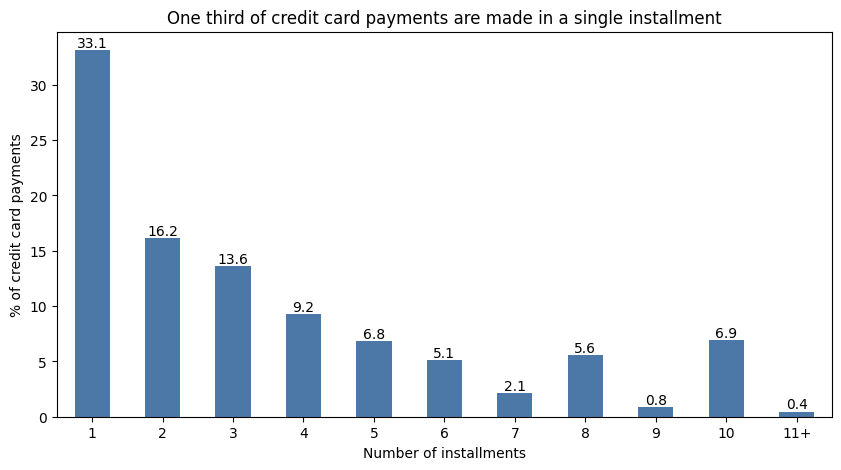

In [121]:
# Plot the results
fig, ax = plt.subplots(figsize=(10, 5))

dist.plot(kind='bar', ax=ax, color='#4C78A8', rot=0, legend=False)

labels = [str(i) for i in dist.index]
labels[-1] = '11+'
ax.set_xticklabels(labels)

ax.set_xlabel('Number of installments')
ax.set_ylabel('% of credit card payments')
ax.set_title('One third of credit card payments are made in a single installment')
ax.bar_label(ax.containers[0], fmt='%.1f')

plt.savefig('installments_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**Findings:**

**Payments:** credit card dominates with 73.92% of payments, followed by boleto
(19.04%), voucher (5.56%) and debit card (1.47%). Only credit card payments use more than one installment.

Among them, the average is 3.51 installments: 33.15% of payments are made in a single installment and the first three options (1–3 installments) account for 62.9%.

There are small peaks at 8 and 10 installments, and fewer than 0.5% of payments exceed 10.

The 11 anomalous payments (9 with value 0 and 2 credit card payments with 0 installments) are kept in the data and flagged. Only the 2 payments with 0 installments are excluded from the installment analysis.

## 8. Wich categories get the best and worst review scores?

In [122]:
# Merge order_items with products
items_cat = order_items.merge(products[['product_id', 'product_category_name']],
                              on='product_id', how='left')
items_cat.shape

(112650, 8)

In [123]:
# Merge the english translation
items_cat = items_cat.merge(product_category, on='product_category_name', how='left')
items_cat.shape

(112650, 9)

In [124]:
# Look for nulls
items_cat['product_category_name_english'].isnull().sum()

np.int64(0)

In [125]:
# Keep one row per order and category
order_category = (items_cat[['order_id', 'product_category_name_english']]
                  .drop_duplicates())
order_category.shape

(99470, 2)

In [126]:
# Merge the reviews per order
order_category = order_category.merge(reviews_per_order[['order_id', 'avg_review_score']],
                                      on='order_id', how='left')
order_category.shape

(99470, 3)

In [127]:
# Look for nulls in average review score
order_category['avg_review_score'].isnull().sum()

np.int64(755)

In [128]:
# Get the mean per category
category_score = (order_category.groupby('product_category_name_english')
                  .agg(avg_review_score=('avg_review_score', 'mean'),
                       n_reviews=('avg_review_score', 'count')).reset_index())

category_score = (category_score[category_score['n_reviews'] >= 100]
                   .sort_values('avg_review_score', ascending=False)
                   .reset_index(drop=True))
category_score.shape

(52, 3)

In [129]:
category_score[category_score['product_category_name_english'] == 'office_furniture']

,product_category_name_english,avg_review_score,n_reviews
51,office_furniture,3.61639,1263


In [130]:
# Prepare the plot
best_10 = category_score.head(10)
worst_10 = category_score.tail(10)
top_bottom = pd.concat([best_10, worst_10])

In [131]:
best_10

,product_category_name_english,avg_review_score,n_reviews
0,books_general_interest,4.462598,508
1,books_technical,4.400778,257
2,food_drink,4.382743,226
3,luggage_accessories,4.331068,1030
4,food,4.276404,445
5,stationery,4.244662,2295
6,pet_shop,4.238095,1701
7,fashion_shoes,4.218220,236
8,perfumery,4.203333,3150
9,costruction_tools_garden,4.190722,194


In [132]:
worst_10

,product_category_name_english,avg_review_score,n_reviews
42,bed_bath_table,3.970740,9313
43,home_construction,3.967146,487
44,fashion_underwear_beach,3.933333,120
45,unknown,3.912787,1439
46,fixed_telephony,3.901869,214
47,home_confort,3.863291,395
48,construction_tools_safety,3.849398,166
49,audio,3.834294,347
50,fashion_male_clothing,3.702703,111
51,office_furniture,3.616390,1263


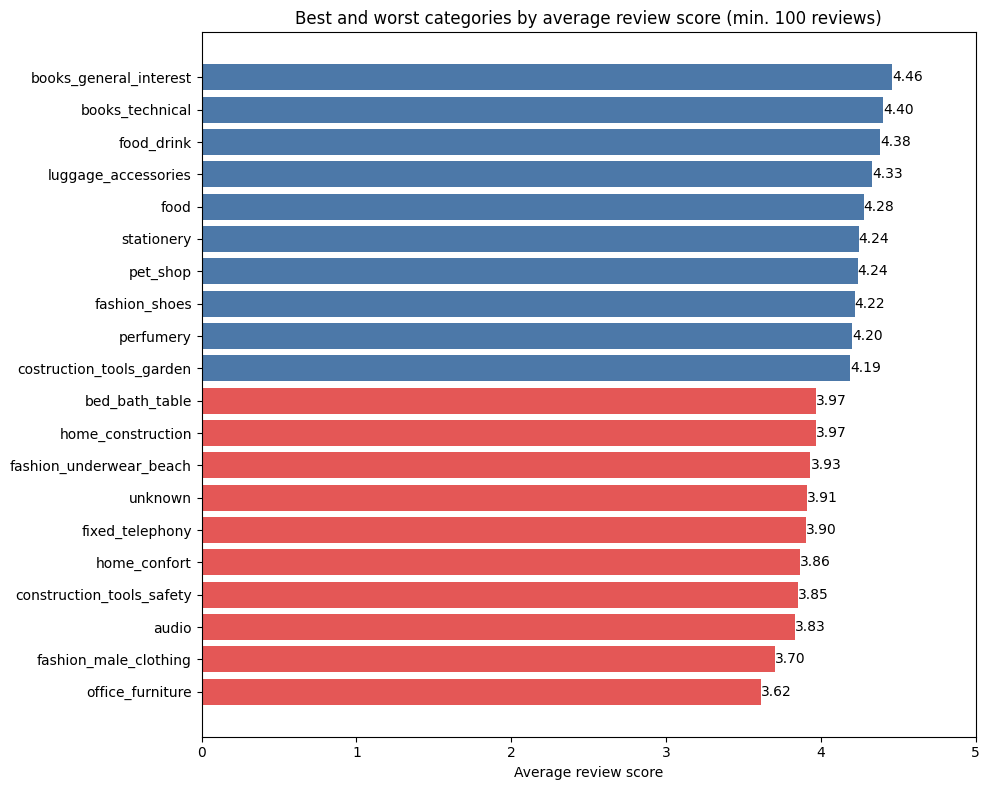

In [133]:
fig, ax = plt.subplots(figsize=(10, 8))

ax.barh(top_bottom['product_category_name_english'],
        top_bottom['avg_review_score'],
        color=['#4C78A8'] * 10 + ['#E45756'] * 10)

ax.set_xlim(0, 5)
ax.invert_yaxis()
ax.set_xlabel('Average review score')
ax.set_title('Best and worst categories by average review score (min. 100 reviews)')
ax.bar_label(ax.containers[0], fmt='%.2f')

plt.tight_layout()
plt.savefig('review_by_category.png', dpi=150, bbox_inches='tight')
plt.show()

**Findings:**

**Review scores by category:** among the 52 categories with at least 100 reviewed orders, average scores range from 3.62 to 4.46, a gap of 0.84 points.

Books, food and luggage are the best rated; office furniture (3.62, 1,263 orders), men's fashion and audio are the worst. bed_bath_table, the largest category (9,313 reviewed orders), sits below the overall average (3.97 vs 4.09).

A low score can come from the product, the delivery or the seller; this analysis cannot separate them, although the delivery analysis above shows that late orders score 1.7 points lower.

## Summary of findings

| # | Question | Main finding | Chart |
|---|---|---|---|
| Q1 | Review scores by category | Scores range from 3.62 to 4.46 across 52 categories; `office_furniture` is the lowest; `bed_bath_table`, the largest category, is below average (3.97 vs 4.09) | `review_by_category.png` |
| Q2 | Revenue by state | SP generates 38.27% of revenue; the top 3 states (SP, RJ, MG) generate 63.4% | `revenue_by_state.png` |
| Q3 | Monthly trend | Orders grew from 787 (Jan 2017) to a peak of 7,423 (Nov 2017) and stabilized in 2018, with a slight revenue decline in mid-2018 | `monthly_trend.png` |
| Q4 | Cancellations | 0.63% of orders are canceled; the monthly rate (0.2%–1.3%) does not follow order volume; differences between states are small (0.30%–0.78%) | `cancellation_rate.png` |
| Q5 | Payments | Credit card is 73.92% of payments; average of 3.51 installments; 33.15% are paid in one installment | `installments_distribution.png` |
| Extra | Delivery vs. review score | 8.1% of orders arrive late and score 2.57 on average vs 4.29 for on-time orders | `delivery_vs_review.png` |